# Laboratorio Final — Starbucks Rewards: del experimento a la decisión

Cierra el bloque de Churn y Uplift Modeling. Van a trabajar con la campaña COMPLETA (no una
muestra de prueba): 40,000 clientes, mitad recibió un cupón de $5 (tratamiento), mitad no
(control), medidos a 60 días.

Este laboratorio repite, sobre la base completa, lo que ya practicaron en los Breakout Rooms:

| Dónde lo vieron | Qué van a repetir aquí |
|---|---|
| Breakout 2 — Las dos ventanas | Un modelo de riesgo/churn, para targetear y ver la pérdida |
| Breakout 3 — Los 4 cuadrantes | El T-learner: dos modelos, uno por grupo |
| Breakout 4 — La curva Qini | Miden qué tan bien ordena su T-learner con datos que nunca vio |

Las columnas `recency_days`, `frequency` y `monetary` son las mismas del RFM de la Semana 1.

**Los 3 pasos del laboratorio:**
1. Entrenan un modelo de churn y lo usan para targetear — van a ver la pérdida con sus
   propios números.
2. Programan el T-learner y miden su Qini.
3. Deciden a quién contactar: eligen el porcentaje óptimo y defienden la cifra.

El dataset trae una columna oculta con el **tipo real de cada cliente y su uplift
verdadero** — en la vida real esa columna no existe. Al final del laboratorio la van a
destapar para ver si sus modelos acertaron.

Donde dice **`# TODO`** hay algo para que ustedes completen.


In [13]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


df = pd.read_csv("data/uplift_campaign.csv")
print(f"{len(df):,} clientes · {(df['treatment_group']=='treatment').sum():,} tratados · {(df['treatment_group']=='control').sum():,} control")
df.head()


40,000 clientes · 19,921 tratados · 20,079 control


,customer_id,treatment_group,recency_days,frequency,monetary,email_open_rate,tenure_days,responded_60d,value_60d,margin_60d,utilidad_neta_60d
0,1,treatment,15,25,615.42,0.230,998,1,38.86,9.72,4.67
1,2,control,30,7,196.12,0.231,551,1,57.20,14.30,14.30
2,3,control,37,1,151.60,0.428,508,0,0.00,0.00,0.00
3,4,control,0,16,449.54,0.386,733,1,24.21,6.05,6.05
4,5,treatment,20,10,393.00,0.796,734,1,23.62,5.91,0.86


## Paso 1 — entrenen un modelo de churn y usen para targetear

Un modelo de churn normal: no sabe nada de tratamiento/control, solo aprende a predecir quién
NO va a volver a comprar. Lo van a usar para elegir a quién contactar (targeting por riesgo) y
van a medir qué tan bien o mal les fue con esa decisión, usando el experimento real como juez.


In [4]:
FEATURES = ["recency_days", "frequency", "monetary", "email_open_rate", "tenure_days"]

train, test = train_test_split(df, test_size=0.30, random_state=42, stratify=df["treatment_group"])

train_churn = train.copy()
train_churn["churned"] = 1 - train_churn["responded_60d"]

# TODO: entrenen el modelo de riesgo/churn con SOLO los datos de entrenamiento
#modelo_riesgo = ...   # <-- reemplacen esto: LogisticRegression(max_iter=1000).fit(X, y)
modelo_riesgo = LogisticRegression(max_iter=1000).fit(train_churn[FEATURES], train_churn["churned"])

test = test.copy()
test["prob_churn"] = modelo_riesgo.predict_proba(test[FEATURES])[:, 1]

print("Modelo de riesgo entrenado")
print("Clientes en entrenamiento:", len(train))
print("Clientes en prueba:", len(test))



Modelo de riesgo entrenado
Clientes en entrenamiento: 28000
Clientes en prueba: 12000


Ahora midan el valor real de targetear por riesgo: tomen el 30% con mayor probabilidad de
churn en el conjunto de prueba, y comparen el valor neto (`utilidad_neta_60d` para los
tratados de ese grupo, contra `margin_60d` del control de ese mismo grupo — su "costo de no
hacer nada").


In [3]:
def valor_de_la_politica(test_df, seleccionados):
    # Valor NETO: margen bruto menos el costo del cupón ($5, solo si compró) y el envío
    # ($0.05, por cualquier tratado) -- la misma fórmula de la slide "El experimento".
    sel = test_df.loc[seleccionados]
    valor_tratado = sel.loc[sel["treatment_group"] == "treatment", "utilidad_neta_60d"].mean()
    valor_control = sel.loc[sel["treatment_group"] == "control", "margin_60d"].mean()
    return valor_tratado - valor_control, len(sel)

n_contactar = int(len(test) * 0.30)
idx_riesgo = test.sort_values("prob_churn", ascending=False).head(n_contactar).index
uplift_riesgo, n_riesgo = valor_de_la_politica(test, idx_riesgo)
print(f"Targeting por riesgo: ${uplift_riesgo:+.2f}/cliente sobre {n_riesgo:,} clientes (total ${uplift_riesgo*n_riesgo:+,.2f})")


Targeting por riesgo: $+0.07/cliente sobre 3,600 clientes (total $+245.40)


## Paso 2 — programen el T-learner y midan su Qini

Dos modelos de **Regresión Logística**: uno entrenado SOLO con los clientes tratados de entrenamiento, otro SOLO con los
de control. Le preguntan a los dos sobre el conjunto de prueba completo, y restan.


In [5]:
train_t = train[train["treatment_group"] == "treatment"]
train_c = train[train["treatment_group"] == "control"]

# TODO: entrenen los dos modelos del T-learner
#modelo_tratado = ...   # <-- reemplacen esto
#modelo_control = ...   # <-- reemplacen esto
modelo_tratado = LogisticRegression(max_iter=1000).fit(train_t[FEATURES], train_t["responded_60d"])
modelo_control = LogisticRegression(max_iter=1000).fit(train_c[FEATURES], train_c["responded_60d"])

X_test = test[FEATURES]
# TODO: puntúen el conjunto de prueba con los dos modelos y calculen el uplift estimado
#test["p_tratado"] = ...        # <-- reemplacen esto
#test["p_control"] = ...        # <-- reemplacen esto
test["p_tratado"] = modelo_tratado.predict_proba(X_test)[:, 1]
test["p_control"] = modelo_control.predict_proba(X_test)[:, 1]

test["uplift_estimado"] = test["p_tratado"] - test["p_control"]

print("T-learner entrenado y conjunto de prueba puntuado")


T-learner entrenado y conjunto de prueba puntuado


In [15]:
def curva_qini(test_df, score_col, steps=40):
    orden = test_df.sort_values(score_col, ascending=False).reset_index(drop=True)
    es_tratado = (orden["treatment_group"] == "treatment").values
    respondio = orden["responded_60d"].values

    acumulado_tratados = np.cumsum(np.where(es_tratado, respondio, 0))
    acumulado_control = np.cumsum(np.where(~es_tratado, respondio, 0))
    n_tratados_acum = np.cumsum(es_tratado)
    n_control_acum = np.cumsum(~es_tratado)

    n = len(orden)
    xs, ys = [0.0], [0.0]
    #for i in np.linspace(1, n, steps).astype(int):
    for i in np.linspace(max(1, int(n * 0.025)), n, steps).astype(int):
        nt, nc = n_tratados_acum[i - 1], n_control_acum[i - 1]
        tasa_t = acumulado_tratados[i - 1] / nt if nt > 0 else 0
        tasa_c = acumulado_control[i - 1] / nc if nc > 0 else 0
        xs.append(i / n)
        ys.append((tasa_t - tasa_c) * i)
    return np.array(xs), np.array(ys)


def coeficiente_qini(xs, ys, n):
    area_modelo = np.trapezoid(ys, xs)
    area_azar = np.trapezoid(np.linspace(0, ys[-1], len(xs)), xs)
    return (area_modelo - area_azar) / n


xs_uplift, ys_uplift = curva_qini(test, "uplift_estimado")
xs_riesgo, ys_riesgo = curva_qini(test, "prob_churn")
qini_uplift = coeficiente_qini(xs_uplift, ys_uplift, len(test))
qini_riesgo = coeficiente_qini(xs_riesgo, ys_riesgo, len(test))

print(f"Coeficiente Qini · T-learner:       {qini_uplift:+.3f}")
print(f"Coeficiente Qini · riesgo/churn:    {qini_riesgo:+.3f}")


Coeficiente Qini · T-learner:       +0.024
Coeficiente Qini · riesgo/churn:    +0.010


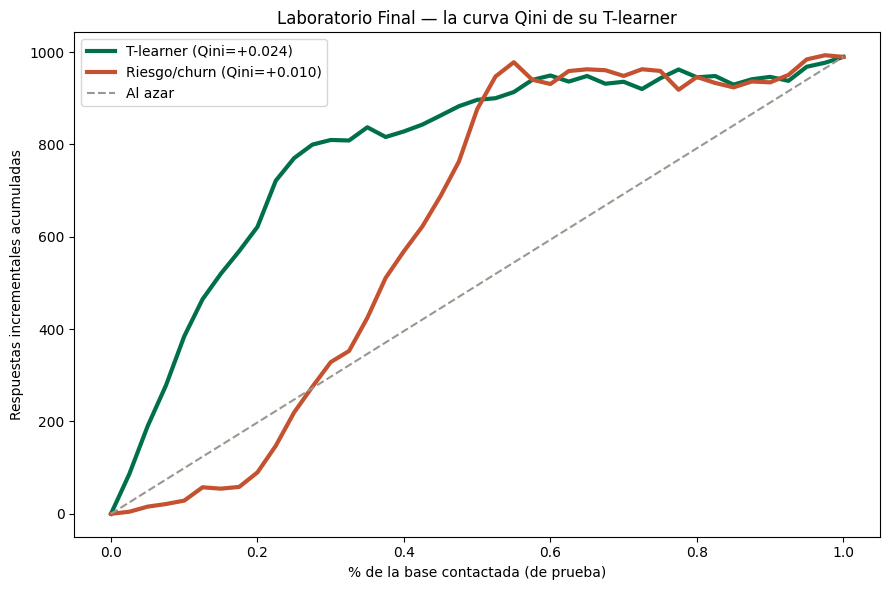

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(xs_uplift, ys_uplift, color="#00704A", linewidth=3, label=f"T-learner (Qini={qini_uplift:+.3f})")
ax.plot(xs_riesgo, ys_riesgo, color="#C4512F", linewidth=3, label=f"Riesgo/churn (Qini={qini_riesgo:+.3f})")
ax.plot([0, 1], [0, ys_uplift[-1]], color="#9A988E", linestyle="--", label="Al azar")
ax.set_xlabel("% de la base contactada (de prueba)")
ax.set_ylabel("Respuestas incrementales acumuladas")
ax.set_title("Laboratorio Final — la curva Qini de su T-learner")
ax.legend()
plt.tight_layout()
plt.savefig("curva_qini_laboratorio.png", dpi=150)
plt.show()


## Paso 3 — decidan a quién contactar

Prueben varios porcentajes de la base (10%, 20%, ..., 100%) ordenados por `uplift_estimado`, y
para cada uno calculen el valor neto total (usando `value_60d`, igual que en el Paso 2).
Encuentren el porcentaje que deja más dinero sobre la mesa.


In [17]:
resultados = []
for pct in range(10, 101, 10):
    n_c = int(len(test) * pct / 100)
    idx = test.sort_values("uplift_estimado", ascending=False).head(n_c).index
    valor_cliente, n = valor_de_la_politica(test, idx)
    resultados.append({"pct_contactado": pct, "valor_por_cliente": round(valor_cliente, 2), "n_contactados": n, "valor_total": round(valor_cliente * n, 2)})

tabla_politicas = pd.DataFrame(resultados)
tabla_politicas


,pct_contactado,valor_por_cliente,n_contactados,valor_total
0,10,1.62,1200,1948.93
1,20,0.99,2400,2368.51
2,30,0.46,3600,1673.33
3,40,-0.10,4800,-500.97
4,50,-0.48,6000,-2899.72
5,60,-0.73,7200,-5260.88
6,70,-0.93,8400,-7853.02
7,80,-1.17,9600,-11226.84
8,90,-1.45,10800,-15687.26
9,100,-1.69,12000,-20236.13


**Pregunta para defender con su propia cifra:** ¿cuál % maximiza el valor TOTAL? ¿Es el mismo
que maximiza el valor POR CLIENTE? ¿Por qué no, necesariamente?


De acuerdo con los resultados obtenidos anteriormente podemos decir que el porcentare que maximiza el valor neto TOTAL es el 20% de los clientes, que es equivalente a 2,400 personas.

Este procentaje no es lo mismo para maximizar el valor por cliente, debido a que al contactar al 10% se obtiene un beneficio promedio de 1.62 dolares por persona, mientras que al usar el 20% se obtiene un promedio de 0.99 dolares por persona.

Esto es ya que los primeros clientes seleccionados generan mayor rentabilidad, al ampliar nos permite acumular un beneficio total.

## La revelación final

Esta es la parte que no pudieron hacer en los Breakout Rooms: el dataset completo
(`uplift_campaign_FULL.csv`) trae el **tipo real** de cada cliente y su **uplift verdadero** —
información que en la vida real nunca existe. Compárenla contra lo que su modelo estimó.


In [18]:
full = pd.read_csv("uplift_campaign_FULL.csv")
full_test = full[full["customer_id"].isin(test["customer_id"])].merge(
    test[["customer_id", "uplift_estimado", "prob_churn"]], on="customer_id"
)

print("Composición real de la base de prueba:")
print((full_test["true_type"].value_counts(normalize=True) * 100).round(1))
print()
print("Correlación entre uplift ESTIMADO y uplift VERDADERO:", round(full_test["uplift_estimado"].corr(full_test["true_uplift_prob"]), 3))


Composición real de la base de prueba:
true_type
sure_thing      48.9
persuadable     22.4
lost_cause      21.5
sleeping_dog     7.2
Name: proportion, dtype: float64

Correlación entre uplift ESTIMADO y uplift VERDADERO: 0.619


In [19]:
modelos = {
    "Regresión logística": LogisticRegression(max_iter=1000),
    "Árbol sin límite": DecisionTreeClassifier(random_state=42),
    "Árbol max_depth=2": DecisionTreeClassifier(
        max_depth=2, random_state=42
        ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=8,
        random_state=42, n_jobs=-1
    )
}

comparacion = []

for nombre, modelo in modelos.items():
    from sklearn.base import clone
    #Los modelos independientes
    mt = clone(modelo)
    mc = clone(modelo)

    mt.fit(train_t[FEATURES], train_t["responded_60d"])
    mc.fit(train_c[FEATURES], train_c["responded_60d"])

    #Uplift de los clientes
    p_t = mt.predict_proba(test[FEATURES])[:, 1]
    p_c = mc.predict_proba(test[FEATURES])[:, 1]

    evaluacion = test.copy()
    evaluacion["uplift_modelo"] = p_t - p_c

    #Evaluar el resultado
    evaluacion = evaluacion.merge(full_test[["customer_id", "true_uplift_prob"]], on="customer_id")

    correlacion = evaluacion["uplift_modelo"].corr(evaluacion["true_uplift_prob"])

    #Calcular Qini
    xs, ys = curva_qini(evaluacion, "uplift_modelo")
    qini = coeficiente_qini(xs, ys, len(evaluacion))

    comparacion.append({
        "Modelo": nombre,
        "Correlación": round(correlacion, 3),
        "Qini": round(qini, 3)
    })

tabla_modelos = pd.DataFrame(comparacion)
display(tabla_modelos)


,Modelo,Correlación,Qini
0,Regresión logística,0.619,0.024
1,Árbol sin límite,0.204,0.010
2,Árbol max_depth=2,0.605,0.020
3,Random Forest,0.860,0.029


Al comparar los 4 modelos de clasificación, podemos concluir que Random Forest obtuvo los mejores resultados, con una correlación de 0.860 y un Qini de 0.029 La regresión logística obtuvo una correlación de 0.619 y un Qini de 0.024, mientras que el árbol con un depth=2 alcanzó 0.605 y 0.020. El árbol sin límite presentó el rendimiento más bajo, posiblemente debido al sobreajuste.

## Para entregar

1. El notebook completo, ejecutado de principio a fin, con sus respuestas a las preguntas de
   cada paso.
2. **Su propia app de Streamlit** (usen `streamlit_starter.py` como punto de partida) que le
   permita a alguien de negocio explorar: el Qini del T-learner y la tabla de
   políticas del Paso 3 — con al menos un control interactivo (slider o selector).
3. Una conclusión de una página: ¿a qué porcentaje de la base contactarían, y por qué? Usen la
   comparación final para decir qué tan cerca estuvo su modelo de la verdad.
4. Cambien el modelo base del T-learner (Árbol de decisión, Random Forest, Gradient Boosting, SVM…) y comparen contra la logística. Cuiden el sobreajuste, por ejemplo con max_depth o min_samples_leaf. ¿Cuál mejora más la correlación del Uplift y el Qini index?
